# Cold–warm: percentile & difference plots

_Plots only — run `cw_calculations.ipynb` first. 20% ranges removed._


In [1]:
# Load Packages
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import calendar
from matplotlib.lines import Line2D
import os
import re
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from scipy.stats import scoreatpercentile
from matplotlib.gridspec import GridSpec
import matplotlib

%matplotlib inline


In [2]:
import sys, os
_p = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_p, 'functions.py')):
        sys.path.insert(0, _p); break
    _p = os.path.dirname(_p)
from functions import *  # shared helper functions


In [8]:
# Load variables computed in cw_calculations.ipynb
load_state(globals())


[load_state] loaded 169 variables from /Users/isabelaconde/Documents/GitHub/JRA55-do_ctrl_ERA5-forcings/processed_data/state.pkl
[load_state] available: DA_all, In, Out, STATE_DIR, STATE_FILE, ax, c, cmap, cmip_xmean, cmip_ymean, cold20_cmip, cold20_cmip_trim ...


{'In': ['',
  '# Load Packages \n\nimport numpy as np\nimport xarray as xr\nimport matplotlib.pyplot as plt\nimport math\nimport cartopy.crs as ccrs\nimport calendar\nfrom matplotlib.lines import Line2D\nimport os\nimport re\nimport seaborn as sns\nimport pandas as pd\nimport matplotlib.gridspec as gridspec\nfrom scipy.stats import norm\n# from mpl_toolkits.basemap import Basemap\nfrom mpl_toolkits.axes_grid1 import make_axes_locatable\nimport matplotlib.patches as patches\nfrom scipy.stats import scoreatpercentile\n# import xesmf as xe\nfrom matplotlib.gridspec import GridSpec\nimport matplotlib\nfrom pathlib import Path',
  "import sys, os\n# make this repo's functions.py importable from any subfolder\n_p = os.getcwd()\nfor _ in range(6):\n    if os.path.exists(os.path.join(_p, 'functions.py')):\n        sys.path.insert(0, _p); break\n    _p = os.path.dirname(_p)\nfrom functions import *  # shared helper functions",
  "# Load variables produced by earlier (compute/loader) notebooks.\

In [10]:
# control_percent_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_control.nc')
# era5_percent_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_era5.nc')
# perturb_percent_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_merra2_percentile_trend.nc')
# # perturb_percent_era5_uas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_percentile_era5_uas_trend.nc')
# perturb_percent_era5_uas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/1deg_jra55_iaf_era5_uas_trend_percentile.nc')
# perturb_percent_era5_uas_vas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_uas_vas.nc')
# perturb_percent_era5_huss_tas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_huss_tas.nc')
# perturb_percent_era5_rsds_rlds_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_rsds_rlds.nc')
# perturb_percent_era5_winds = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_era5_winds.nc')
# perturb_percent_all_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_all_trend.nc')
# perturb_percent_winds_mean_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_percentile_trend_uas_vas_mean_trend.nc')


# Plots 

1. trend at each percent plot 
2. trend at each percent difference from era5

Text(0.5, 1.0, 'Trend at Each SST Percentile (1982–2017)')

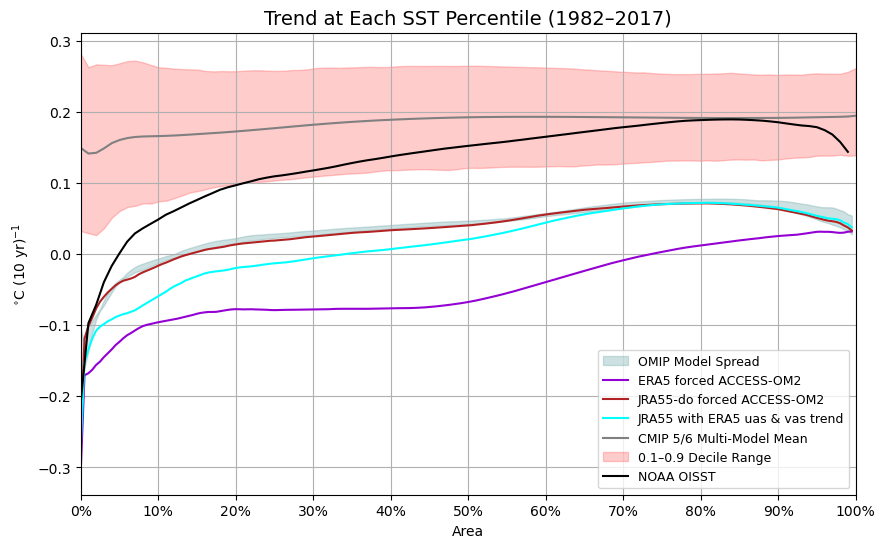

In [14]:
fig, axes = plt.subplots(figsize=(10, 6))

# -------------------------
# OMIP SHADED REGION (exclude last model)
# -------------------------
omip_models = mod_labs[:-1]          # all except last
special_mod = mod_labs[-1]           # last model (plot separately)

# Stack all OMIP models
omip_stack = xr.concat(
    [percentiles_omip_trend[m] for m in omip_models],
    dim='model'
) * 12 * 10

# Ensemble stats
omip_min  = omip_stack.min(dim='model')
omip_max  = omip_stack.max(dim='model')
omip_mean = omip_stack.mean(dim='model')

# Shaded region
axes.fill_between(
    omip_stack.area,
    omip_min,
    omip_max,
    color='cadetblue',
    alpha=0.3,
    label='OMIP Model Spread'
)

# # Optional OMIP mean line
# axes.plot(
#     omip_stack.area,
#     omip_mean,
#     color='orange',
#     lw=2,
#     label='OMIP Mean'
# )

# -------------------------
# SPECIAL MODEL (last entry)
# -------------------------
(era5_percent_trend * 12 * 10).plot(
    ax=axes,
    color='darkviolet',
    label='ERA5 forced ACCESS-OM2',
    lw=1.5
)

# -------------------------
# ACCESS-OM2 runs
# -------------------------
(control_percent_trend*12*10).plot(ax=axes, label='JRA55-do forced ACCESS-OM2', color='firebrick',lw=1.5)
# (perturb_percent_era5_uas_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 uas trend', color='cyan')
(perturb_percent_era5_uas_vas_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 uas & vas trend', color='cyan')
# (perturb_percent_era5_rsds_rlds_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 rsds & rlds trend', color='indianred')
# ((perturb_percent_era5_huss_tas_trend)*12*10).plot(ax=axes, label='JRA55 with ERA5 huss & tas trend', color='limegreen')
# ((perturb_percent_era5_winds)*12*10).plot(ax=axes, label='JRA55 with ERA5 winds trend', color='violet')
# ((perturb_percent_all_trend)*12*10).plot(ax=axes, label='JRA55 with ERA5 all-ish trends', color='orange',lw = 1.5)
# (perturb_percent_cm2_winds_trend*12*10).plot(ax=axes, label='JRA55-do forced with CM2 uas & vas trend', color='blue',lw = 1.5)

# (cm2_percent_trend*10*12).plot(ax=axes, label='ACCESS-CM2', color='red')
# -------------------------
# CMIP + envelope
# -------------------------
sns.lineplot(x="area", y="mean", data=df, ax=axes, color='grey', label='CMIP 5/6 Multi-Model Mean')
axes.fill_between(df['area'], df['upper'], df['lower'], alpha=0.2, color='red',
                  label='0.1–0.9 Decile Range')

# NOAA observational line
axes.plot(noaa_sst_trend.area.values, noaa_sst_trend.values * 10 * 12,
          color='k', label='NOAA OISST')

# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f'{int(x*100)}%' for x in np.linspace(0, 1, 11)])
axes.grid(True)
axes.legend(loc='lower right', fontsize=9)
axes.set_xlim(0, 1)
axes.set_ylabel(r'$^{\circ}$C (10 yr)$^{-1}$')
axes.set_xlabel('Area')
plt.title('Trend at Each SST Percentile (1982–2017)', fontsize=14)


Text(0.5, 1.0, 'Trend at Each SST Percentile (1982–2017)')

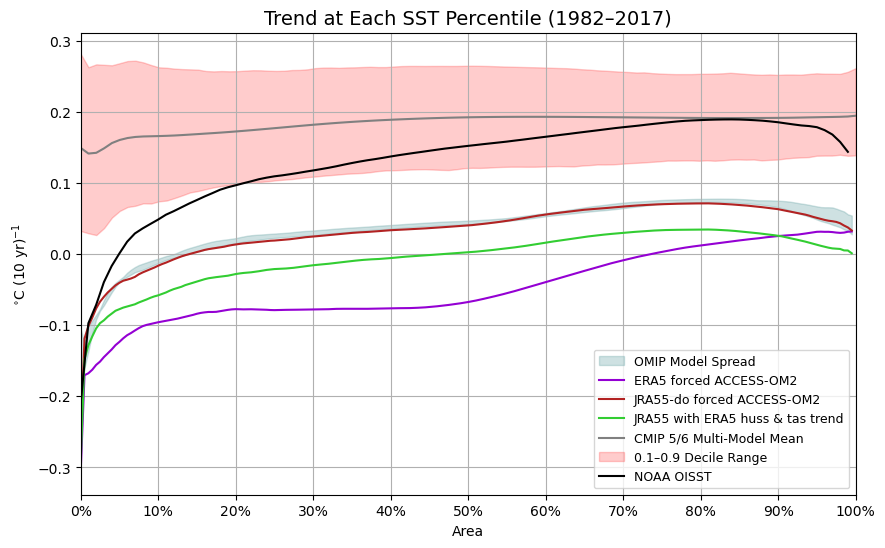

In [15]:
fig, axes = plt.subplots(figsize=(10, 6))

# -------------------------
# OMIP SHADED REGION (exclude last model)
# -------------------------
omip_models = mod_labs[:-1]          # all except last
special_mod = mod_labs[-1]           # last model (plot separately)

# Stack all OMIP models
omip_stack = xr.concat(
    [percentiles_omip_trend[m] for m in omip_models],
    dim='model'
) * 12 * 10

# Ensemble stats
omip_min  = omip_stack.min(dim='model')
omip_max  = omip_stack.max(dim='model')
omip_mean = omip_stack.mean(dim='model')

# Shaded region
axes.fill_between(
    omip_stack.area,
    omip_min,
    omip_max,
    color='cadetblue',
    alpha=0.3,
    label='OMIP Model Spread'
)

# # Optional OMIP mean line
# axes.plot(
#     omip_stack.area,
#     omip_mean,
#     color='orange',
#     lw=2,
#     label='OMIP Mean'
# )

# -------------------------
# SPECIAL MODEL (last entry)
# -------------------------
(era5_percent_trend * 12 * 10).plot(
    ax=axes,
    color='darkviolet',
    label='ERA5 forced ACCESS-OM2',
    lw=1.5
)

# -------------------------
# ACCESS-OM2 runs
# -------------------------
(control_percent_trend*12*10).plot(ax=axes, label='JRA55-do forced ACCESS-OM2', color='firebrick',lw=1.5)
# (perturb_percent_era5_uas_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 uas trend', color='cyan')
# (perturb_percent_era5_uas_vas_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 uas & vas trend', color='cyan')
# (perturb_percent_era5_rsds_rlds_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 rsds & rlds trend', color='indianred',lw=1)
((perturb_percent_era5_huss_tas_trend)*12*10).plot(ax=axes, label='JRA55 with ERA5 huss & tas trend', color='limegreen')
# ((perturb_percent_era5_winds)*12*10).plot(ax=axes, label='JRA55 with ERA5 winds trend', color='violet')
# ((perturb_percent_all_trend)*12*10).plot(ax=axes, label='JRA55 with ERA5 all-ish trends', color='orange',lw = 1.5)
# (perturb_percent_cm2_winds_trend*12*10).plot(ax=axes, label='JRA55-do forced with CM2 uas & vas trend', color='blue',lw = 1.5)
# (perturb_percent_cm2_huss_tas_trend*12*10).plot(ax=axes, label='JRA55-do forced with CM2 huss & tas trend', color='green',lw = 1.5)
# (cm2_percent_trend*10*12).plot(ax=axes, label='ACCESS-CM2', color='red')
# -------------------------
# CMIP + envelope
# -------------------------
sns.lineplot(x="area", y="mean", data=df, ax=axes, color='grey', label='CMIP 5/6 Multi-Model Mean')
axes.fill_between(df['area'], df['upper'], df['lower'], alpha=0.2, color='red',
                  label='0.1–0.9 Decile Range')

# NOAA observational line
axes.plot(noaa_sst_trend.area.values, noaa_sst_trend.values * 10 * 12,
          color='k', label='NOAA OISST')

# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f'{int(x*100)}%' for x in np.linspace(0, 1, 11)])
axes.grid(True)
axes.legend(loc='lower right', fontsize=9)
axes.set_xlim(0, 1)
axes.set_ylabel(r'$^{\circ}$C (10 yr)$^{-1}$')
axes.set_xlabel('Area')
plt.title('Trend at Each SST Percentile (1982–2017)', fontsize=14)


# difference 

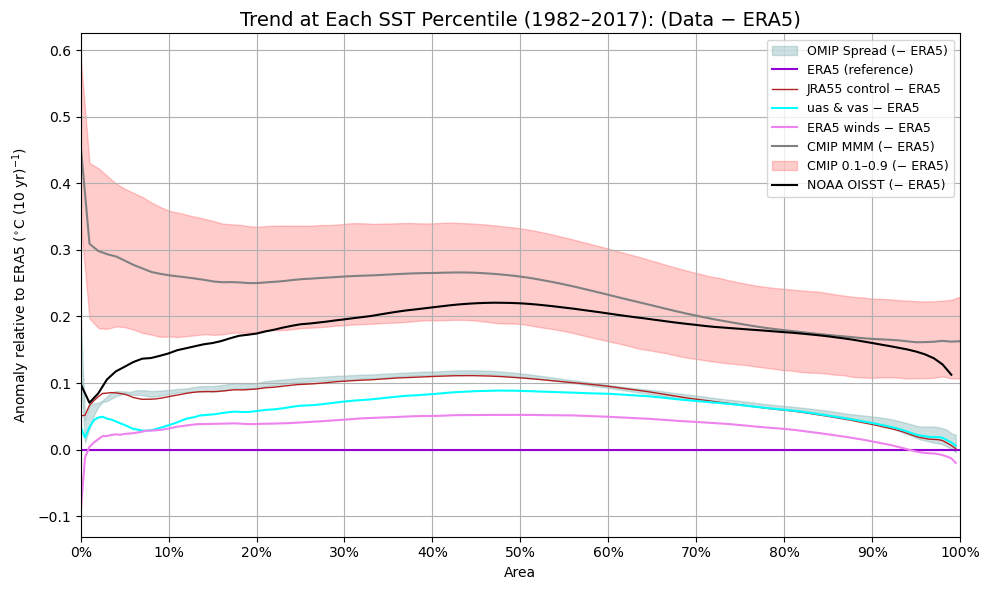

In [7]:
fig, axes = plt.subplots(figsize=(10, 6))

# Reference (ERA5) in °C/10yr
ref = era5_percent_trend
ref10 = ref * 12 * 10

# -------------------------
# OMIP SHADED REGION (relative to ERA5)
# -------------------------
omip_models = mod_labs[:-1]
special_mod = mod_labs[-1]  # unused now, but kept

omip_stack = xr.concat([percentiles_omip_trend[m] for m in omip_models], dim="model")
omip_stack_diff = (omip_stack - ref) * 12 * 10

omip_min  = omip_stack_diff.min(dim="model")
omip_max  = omip_stack_diff.max(dim="model")
omip_mean = omip_stack_diff.mean(dim="model")

axes.fill_between(
    omip_stack_diff.area,
    omip_min,
    omip_max,
    color="cadetblue",
    alpha=0.3,
    label="OMIP Spread (− ERA5)"
)

# optional: OMIP mean (relative)
# axes.plot(omip_stack_diff.area, omip_mean, color="orange", lw=2, label="OMIP Mean (− ERA5)")

# -------------------------
# ERA5 reference line at zero
# -------------------------
axes.axhline(0, color="darkviolet", lw=1.5, label="ERA5 (reference)")

# -------------------------
# ACCESS-OM2 runs (relative to ERA5)
# -------------------------
((control_percent_trend - ref) * 12 * 10).plot(ax=axes, label="JRA55 control − ERA5", color="firebrick", lw=1)
((perturb_percent_era5_uas_vas_trend - ref) * 12 * 10).plot(ax=axes, label="uas & vas − ERA5", color="cyan")
# ((perturb_percent_era5_rsds_rlds_trend - ref) * 12 * 10).plot(ax=axes, label="rsds & rlds − ERA5", color="orangered", lw=1)
# ((perturb_percent_era5_huss_tas_trend - ref) * 12 * 10).plot(ax=axes, label="huss & tas − ERA5", color="limegreen")
((perturb_percent_era5_winds - ref) * 12 * 10).plot(ax=axes, label="ERA5 winds − ERA5", color="violet")
# ((perturb_percent_all_trend - ref) * 12 * 10).plot(ax=axes, label="all-ish − ERA5", color="orange", lw=1.5)

# -------------------------
# CMIP mean + envelope (relative to ERA5)
# df columns assumed already in °C/10yr on x="area"
# -------------------------
ref_on_df = np.interp(df["area"].values, ref10.area.values, ref10.values)

df_rel = df.copy()
df_rel["mean"]  = df_rel["mean"]  - ref_on_df
df_rel["upper"] = df_rel["upper"] - ref_on_df
df_rel["lower"] = df_rel["lower"] - ref_on_df

sns.lineplot(x="area", y="mean", data=df_rel, ax=axes, color="grey", label="CMIP MMM (− ERA5)")
axes.fill_between(df_rel["area"], df_rel["upper"], df_rel["lower"], alpha=0.2, color="red",
                  label="CMIP 0.1–0.9 (− ERA5)")

# -------------------------
# NOAA observational line (relative to ERA5)
# -------------------------
noaa10 = noaa_sst_trend * 10 * 12
(noaa10 - ref10).plot(ax=axes, color="k", label="NOAA OISST (− ERA5)")

# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f"{int(x*100)}%" for x in np.linspace(0, 1, 11)])
axes.grid(True)
axes.legend(loc="upper right", fontsize=9)
axes.set_xlim(0, 1)
axes.set_ylabel(r"Anomaly relative to ERA5 ($^{\circ}$C (10 yr)$^{-1}$)")
axes.set_xlabel("Area")
plt.title("Trend at Each SST Percentile (1982–2017): (Data − ERA5)", fontsize=14)
plt.tight_layout()


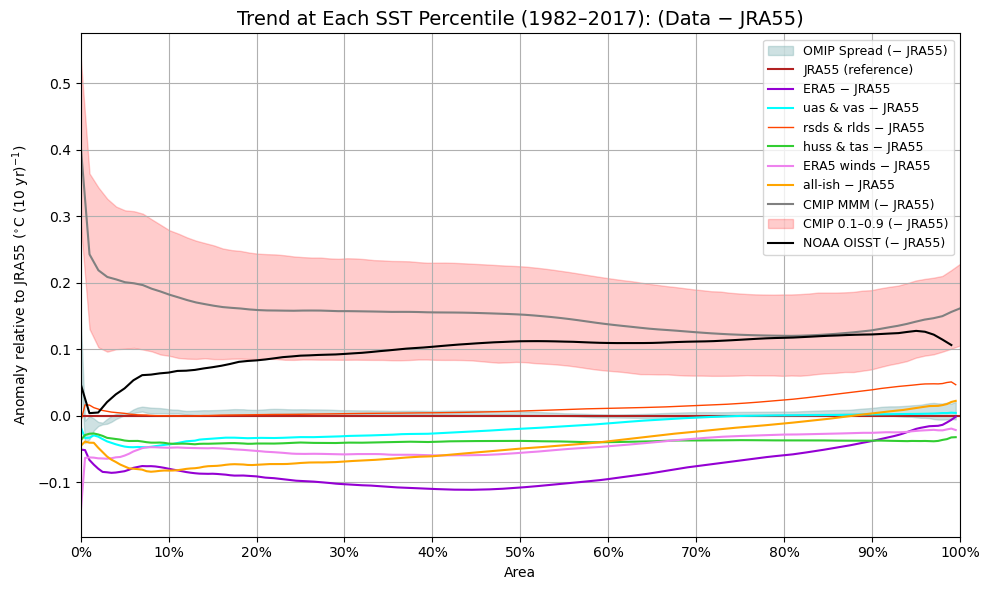

In [6]:
fig, axes = plt.subplots(figsize=(10, 6))

# Reference (JRA55 control) in °C/10yr
ref = control_percent_trend
ref10 = ref * 12 * 10

# -------------------------
# OMIP SHADED REGION (relative to JRA55)
# -------------------------
omip_models = mod_labs[:-1]

omip_stack = xr.concat([percentiles_omip_trend[m] for m in omip_models], dim="model")
omip_stack_diff = (omip_stack - ref) * 12 * 10

omip_min  = omip_stack_diff.min(dim="model")
omip_max  = omip_stack_diff.max(dim="model")
omip_mean = omip_stack_diff.mean(dim="model")

axes.fill_between(
    omip_stack_diff.area,
    omip_min,
    omip_max,
    color="cadetblue",
    alpha=0.3,
    label="OMIP Spread (− JRA55)"
)

# -------------------------
# JRA55 reference line at zero
# -------------------------
axes.axhline(0, color="firebrick", lw=1.5, label="JRA55 (reference)")

# -------------------------
# Other lines (relative to JRA55)
# -------------------------
((era5_percent_trend - ref) * 12 * 10).plot(ax=axes, label="ERA5 − JRA55", color="darkviolet", lw=1.5)
((perturb_percent_era5_uas_vas_trend - ref) * 12 * 10).plot(ax=axes, label="uas & vas − JRA55", color="cyan")
((perturb_percent_era5_rsds_rlds_trend - ref) * 12 * 10).plot(ax=axes, label="rsds & rlds − JRA55", color="orangered", lw=1)
((perturb_percent_era5_huss_tas_trend - ref) * 12 * 10).plot(ax=axes, label="huss & tas − JRA55", color="limegreen")
((perturb_percent_era5_winds - ref) * 12 * 10).plot(ax=axes, label="ERA5 winds − JRA55", color="violet")
((perturb_percent_all_trend - ref) * 12 * 10).plot(ax=axes, label="all-ish − JRA55", color="orange", lw=1.5)

# -------------------------
# CMIP mean + envelope (relative to JRA55)
# df columns assumed already in °C/10yr on x="area"
# -------------------------
ref_on_df = np.interp(df["area"].values, ref10.area.values, ref10.values)

df_rel = df.copy()
df_rel["mean"]  = df_rel["mean"]  - ref_on_df
df_rel["upper"] = df_rel["upper"] - ref_on_df
df_rel["lower"] = df_rel["lower"] - ref_on_df

sns.lineplot(x="area", y="mean", data=df_rel, ax=axes, color="grey", label="CMIP MMM (− JRA55)")
axes.fill_between(df_rel["area"], df_rel["upper"], df_rel["lower"], alpha=0.2, color="red",
                  label="CMIP 0.1–0.9 (− JRA55)")

# -------------------------
# NOAA observational line (relative to JRA55)
# -------------------------
noaa10 = noaa_sst_trend * 10 * 12
(noaa10 - ref10).plot(ax=axes, color="k", label="NOAA OISST (− JRA55)")

# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f"{int(x*100)}%" for x in np.linspace(0, 1, 11)])
axes.grid(True)
axes.legend(loc="upper right", fontsize=9)
axes.set_xlim(0, 1)
axes.set_ylabel(r"Anomaly relative to JRA55 ($^{\circ}$C (10 yr)$^{-1}$)")
axes.set_xlabel("Area")
plt.title("Trend at Each SST Percentile (1982–2017): (Data − JRA55)", fontsize=14)
plt.tight_layout()
